# 10. Policy Analysis: Risk × Value Targeting

Builds on notebooks 07-09 (unchanged). Adds what the evaluation chapter was
missing: **validation predictions from a train-only model**, a
**risk × value diagnosis** of why churn-only targeting trailed the recency
rule, **segment-level actions**, and **policy simulation under Strategy v2**
(Sections 7.7-7.9): E[ΔM] = p·e·V·(m−d) − (1−p)·r·V·d − c.

All £ figures are **scenario estimates** (no treatment/control data); policy
*ranking* is more reliable than absolute levels. Amounts are reported **per
week** (mean over scoring weeks), not summed over overlapping 90-day windows.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from policy_lib import *

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e5e5e0"})
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"

# Business assumptions (Strategy v2, Section 2.10)
BASE = dict(d=0.10, e=0.30, m=0.40, r=0.40, c=0.50)
SCENARIOS = {"Light": (0.05, 0.20), "Base": (0.10, 0.30), "Deep": (0.20, 0.40)}
K_GRID = [0.10, 0.20, 0.30, 0.40, 0.50]

## 10.1 Load and integrity checks

In [2]:
data = pd.read_parquet("../data/processed/modeling_dataset_h90.parquet")
scores = pd.read_parquet("../data/results/churn_scores_h90.parquet")  # notebook 09 output
key = ["customer_id", "snapshot_date"]

assert not data.duplicated(key).any(), "duplicate (customer, snapshot) in dataset"
assert not scores.duplicated(key).any(), "duplicate (customer, snapshot) in scores"
test_raw = data[data.split == "test"]
chk = test_raw.merge(scores[scores.split == "test"][key + ["churn_probability", "churn"]],
                     on=key, how="outer", indicator=True, suffixes=("", "_s"))
print("test rows dataset / scores:", len(test_raw), (scores.split == "test").sum())
print("merge status:", chk["_merge"].value_counts().to_dict())
print("label mismatch:", int((chk.churn != chk.churn_s).sum()))
print("model_version in scores:", scores.model_version.unique())
print(data.groupby("split").agg(rows=("churn", "size"), weeks=("snapshot_date", "nunique"),
      customers=("customer_id", "nunique"), churn=("churn", "mean")).round(3))

test rows dataset / scores: 24252 24252
merge status: {'both': 24252, 'left_only': 0, 'right_only': 0}
label mismatch: 0
model_version in scores: ['lr_extended_c0.01_weighted_h90']
             rows  weeks  customers  churn
split                                     
test        24252     10       2907  0.401
train       61415     24       3905  0.430
validation  21514      8       3328  0.529


## 10.2 Train-only predictions and calibration check

The scores from notebook 09 come from a model refit on train **+ validation**,
so they cannot be used to choose a policy on validation. Here the same recipe
is fitted on **train only**; validation and test predictions are out-of-sample.

In [3]:
train = data[data.split == "train"]
val = data[data.split == "validation"].copy()
test = data[data.split == "test"].copy()
predict, lr = fit_train_only(train)
val["p"], test["p"] = predict(val), predict(test)

rows = {}
for name, df in [("validation", val), ("test", test)]:
    rows[name] = dict(churn_rate=df.churn.mean(), mean_p=df.p.mean(),
                      roc_auc=roc_auc_score(df.churn, df.p),
                      pr_auc=average_precision_score(df.churn, df.p),
                      brier=brier_score_loss(df.churn, df.p),
                      brier_base_rate=brier_score_loss(df.churn, np.full(len(df), df.churn.mean())))
pd.DataFrame(rows).T.round(3)

,churn_rate,mean_p,roc_auc,pr_auc,brier,brier_base_rate
validation,0.529,0.444,0.779,0.770,0.198,0.249
test,0.401,0.372,0.754,0.645,0.197,0.240


In [4]:
# Calibration: fit on validation, check on test
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
iso = IsotonicRegression(out_of_bounds="clip").fit(val.p, val.churn)
platt = LogisticRegression(C=1e6).fit(logit(val.p).values.reshape(-1, 1), val.churn)
test["p_iso"] = iso.predict(test.p)
test["p_platt"] = platt.predict_proba(logit(test.p).values.reshape(-1, 1))[:, 1]
pd.DataFrame({c: dict(mean_p=test[c].mean(), brier=brier_score_loss(test.churn, test[c]),
                      roc_auc=roc_auc_score(test.churn, test[c]))
              for c in ["p", "p_platt", "p_iso"]}).T.round(4)

,mean_p,brier,roc_auc
p,0.3719,0.1971,0.7537
p_platt,0.4512,0.1991,0.7537
p_iso,0.4515,0.1991,0.7536


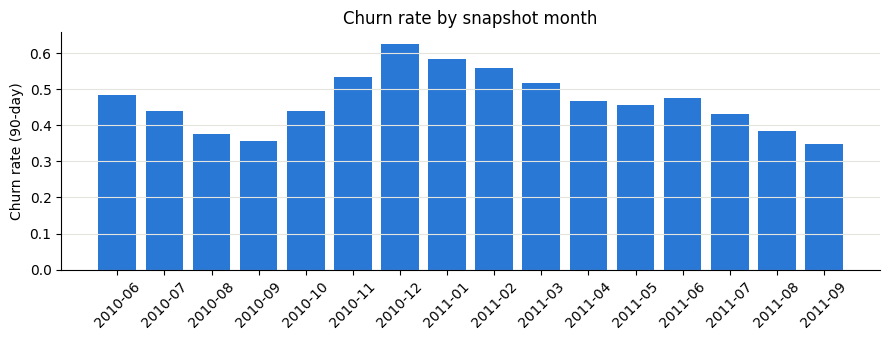

In [5]:
# Why calibration on validation does not transfer: the base churn rate moves with the season
lab = data[data.labelable]
monthly = lab.groupby(lab.snapshot_date.dt.to_period("M")).churn.mean()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(monthly.index.astype(str), monthly.values, color=BLUE)
ax.set_ylabel("Churn rate (90-day)"); ax.set_title("Churn rate by snapshot month")
plt.xticks(rotation=45); fig.tight_layout()
fig.savefig("../report/figures/ch10_churn_by_month.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading.** Validation (Feb-Apr 2011) has a 53% churn rate, test (Jul-Sep) 40%.
A calibrator fitted on validation learns that higher base rate and *worsens*
Brier on test. Within a period the train-only model is roughly calibrated;
across seasons the level shifts. The ranking is stable (AUC ≈ 0.75-0.78), so
policies below use the **raw** probability `p`; absolute £ should be read with
this in mind.

## 10.3 Churn-only vs recency: who do they pick?

Top 10% each week by (a) model probability and (b) recency (days since last
purchase). Groups: picked by both, only by the model, only by recency.

In [6]:
K = 0.10
def overlap_profile(df):
    mm, mr = top_k_mask(df, "p", K), top_k_mask(df, "recency_days", K)
    groups = {"both": mm & mr, "only_model": mm & ~mr, "only_recency": mr & ~mm, "all active": df.index == df.index}
    out = {}
    for g, m in groups.items():
        x = df[m]
        out[g] = dict(rows=len(x), churn_rate=x.churn.mean(), mean_p=x.p.mean(),
                      value_v_mean=x.value_v.mean(), value_v_median=x.value_v.median(),
                      recency_median=x.recency_days.median(), frequency_median=x.frequency_so_far.median(),
                      one_time_share=(x.segment == "one-time").mean())
    return pd.DataFrame(out).T, (mm & mr).sum() / mm.sum()
for name, df in [("validation", val), ("test", test)]:
    prof, ov = overlap_profile(df)
    print(f"{name}: share of model top-{K:.0%} also in recency top-{K:.0%} = {ov:.1%}")
    display(prof.round(3))

validation: share of model top-10% also in recency top-10% = 32.8%


,rows,churn_rate,mean_p,value_v_mean,value_v_median,recency_median,frequency_median,one_time_share
both,705.0,0.867,0.790,241.743,220.970,129.805,1.0,0.841
only_model,1447.0,0.833,0.783,187.826,172.600,108.651,1.0,0.890
only_recency,1447.0,0.674,0.589,414.217,310.770,129.618,3.0,0.066
all active,21514.0,0.529,0.444,367.139,296.465,65.891,4.0,0.194


test: share of model top-10% also in recency top-10% = 38.0%


,rows,churn_rate,mean_p,value_v_mean,value_v_median,recency_median,frequency_median,one_time_share
both,923.0,0.779,0.767,257.290,206.210,123.597,1.0,0.662
only_model,1504.0,0.727,0.739,181.122,144.300,80.607,1.0,0.842
only_recency,1504.0,0.533,0.495,395.923,318.812,121.951,5.0,0.007
all active,24252.0,0.401,0.372,373.689,303.583,42.863,5.0,0.133


**Reading.** The two rules share only about a third of their picks. The
model's exclusive picks are low-value, low-frequency customers (many
one-time buyers) with a *higher* churn rate than recency's exclusive picks,
while recency's exclusive picks are repeat customers with roughly 2× the
value. Churn-only targeting finds more churners but with less money behind
each; value-weighted rules correct for it.

In [7]:
# Same question from the outcome side: where does each rule's 'catch' come from, and how concentrated is value?
mm = top_k_mask(test, "p", K); mr = top_k_mask(test, "recency_days", K)
rev = lambda m: test[m & (test.churn == 1)].value_v.sum()
print(f"Revenue-at-risk among captured churners (sum of value_v, weekly rows): model {rev(mm):,.0f} | recency {rev(mr):,.0f}")
print(f"Churners captured: model {int((mm & (test.churn==1)).sum()):,} | recency {int((mr & (test.churn==1)).sum()):,}")
top1 = test.groupby("customer_id").avg_order_value_so_far.max().nlargest(int(0.01 * test.customer_id.nunique())).index
print("top-1% customers by raw AOV (wholesale-like):", len(top1), "| share of test rows:", round(test.customer_id.isin(top1).mean(), 3),
      "| share of raw value among row-weighted revenue:", round(test[test.customer_id.isin(top1)].avg_order_value_so_far.sum() / test.avg_order_value_so_far.sum(), 3))

Revenue-at-risk among captured churners (sum of value_v, weekly rows): model 374,741 | recency 492,349
Churners captured: model 1,813 | recency 1,521
top-1% customers by raw AOV (wholesale-like): 29 | share of test rows: 0.011 | share of raw value among row-weighted revenue: 0.108


## 10.4 RFM segments → actions

Per-customer realized margin if a segment is offered (base scenario), using
actual labels. The action is chosen on **validation** and then checked on
**test**; segment names are not used to assign actions.

In [8]:
def row_gain(df, d, e, m, r, c, vcol="value_v"):
    v = df[vcol]
    return np.where(df.churn == 1, e * v * (m - d), -r * v * d) - c

val["gain"] = row_gain(val, **{k: BASE[k] for k in "d e m r c".split()})
test["gain"] = row_gain(test, **{k: BASE[k] for k in "d e m r c".split()})
def seg_table(df):
    return df.groupby("rfm_segment").agg(share=("gain", lambda s: len(s) / len(df)), churn=("churn", "mean"),
            mean_p=("p", "mean"), value_v=("value_v", "mean"), gain_per_customer=("gain", "mean"))
seg_val, seg_test = seg_table(val), seg_table(test)
seg = seg_val.add_suffix("_val").join(seg_test.add_suffix("_test"))
seg["action"] = np.where((seg.gain_per_customer_val > 0) & (seg.gain_per_customer_test > 0), "Offer",
                  np.where((seg.gain_per_customer_val < 0) & (seg.gain_per_customer_test < 0), "No discount", "Unstable: low-cost contact"))
seg.round(3)

,share_val,churn_val,mean_p_val,value_v_val,gain_per_customer_val,share_test,churn_test,mean_p_test,value_v_test,gain_per_customer_test,action
rfm_segment,,,,,,,,,,,
At Risk,0.227,0.672,0.548,363.808,17.579,0.153,0.584,0.516,348.325,12.520,Offer
Can't Lose,0.149,0.386,0.313,434.299,2.197,0.166,0.299,0.288,429.757,-1.620,Unstable: low-cost contact
Champions,0.210,0.237,0.175,451.922,-5.214,0.276,0.212,0.162,434.849,-6.582,No discount
Hibernating,0.184,0.837,0.742,243.959,16.512,0.119,0.721,0.718,246.947,11.857,Offer
Loyal,0.097,0.300,0.239,432.465,-2.112,0.138,0.286,0.234,408.520,-2.797,No discount
Potential,0.133,0.646,0.579,285.855,11.482,0.149,0.523,0.557,292.905,6.492,Offer


**Reading.** Offers pay off for At Risk, Hibernating and Potential (high churn
probability → recovered margin outweighs discount given to buyers anyway).
Champions and Loyal lose margin per customer (mostly would-have-bought-anyway
→ cannibalization). **Can't Lose** — whose name suggests a rescue offer — has a
churn rate of only 29-39%, so a discount loses or barely breaks even; treat it
with a low-cost contact, not a discount. The segment name alone would have
given the wrong action.

## 10.5 Policy simulation (P0-P6)

Weekly Top-K from the Scoring Population (every active customer each week).
`E[ΔM]` uses the train-only probability `p`. P6 additionally requires
E[ΔM] > 0. P4 targets At Risk + Can't Lose (strategy definition) and P4b the
segments chosen by validation in 10.4. Reported: **weekly net margin, mean ± std over weeks**.

In [9]:
def policy_masks(df, k, scen):
    d, e, m, r, c = scen
    df = df.assign(em=expected_margin(df.p, df.value_v, d, e, m, r, c), rand=np.random.default_rng(0).uniform(size=len(df)))
    masks = {
        "P0 No offer": pd.Series(False, index=df.index),
        "P1 Blanket": pd.Series(True, index=df.index),
        "P2 Random": top_k_mask(df, "rand", k),
        "P3 Recency": top_k_mask(df, "recency_days", k),
        "P4 RFM At Risk+Can't Lose": df.rfm_segment.isin(["At Risk", "Can't Lose"]),
        "P4b RFM validated segments": df.rfm_segment.isin(seg.index[seg.action == "Offer"]),
        "P5 Model risk-only": top_k_mask(df, "p", k),
        "P6 Model value-aware": top_k_mask(df, "em", k) & (df.em > 0),
    }
    return df, masks

def weekly_margin(df, mask, scen):
    d, e, m, r, c = scen
    g = pd.Series(row_gain(df, d, e, m, r, c), index=df.index)
    weeks = df.snapshot_date.unique()
    return g[mask].groupby(df.snapshot_date[mask]).sum().reindex(weeks, fill_value=0)

def policy_table(df, k, scen):
    df, masks = policy_masks(df, k, scen)
    rows = {}
    for name, mk in masks.items():
        w = weekly_margin(df, mk, scen)
        n_week = mk.groupby(df.snapshot_date).sum()
        rows[name] = dict(customers_per_week=n_week.mean(), margin_week_mean=w.mean(), margin_week_std=w.std(), worst_week=w.min(),
                          precision=df[mk].churn.mean() if mk.any() else np.nan,
                          would_be_buyers_share=1 - df[mk].churn.mean() if mk.any() else np.nan)
    return pd.DataFrame(rows).T

SC_BASE = (BASE["d"], BASE["e"], BASE["m"], BASE["r"], BASE["c"])
K_OP = 0.20
print("VALIDATION (selection), base scenario, K=20%"); display(policy_table(val, K_OP, SC_BASE).round(2))
print("TEST (final evaluation), base scenario, K=20%"); display(policy_table(test, K_OP, SC_BASE).round(2))

VALIDATION (selection), base scenario, K=20%


,customers_per_week,margin_week_mean,margin_week_std,worst_week,precision,would_be_buyers_share
P0 No offer,0.00,0.00,0.00,0.00,NaN,NaN
P1 Blanket,2689.25,20380.95,4621.81,14668.32,0.53,0.47
P2 Random,537.88,4314.29,1471.83,2637.62,0.53,0.47
P3 Recency,537.88,9402.40,1572.95,7194.30,0.73,0.27
P4 RFM At Risk+Can't Lose,1011.75,11627.27,2573.59,8170.03,0.56,0.44
P4b RFM validated segments,1462.38,23002.23,4902.87,16259.14,0.72,0.28
P5 Model risk-only,537.88,8442.40,1208.48,6594.92,0.81,0.19
P6 Model value-aware,537.88,14768.78,2727.13,11164.65,0.75,0.25


TEST (final evaluation), base scenario, K=20%


,customers_per_week,margin_week_mean,margin_week_std,worst_week,precision,would_be_buyers_share
P0 No offer,0.0,0.00,0.00,0.00,NaN,NaN
P1 Blanket,2425.2,4419.86,3265.61,-1036.92,0.40,0.60
P2 Random,485.0,1123.65,1050.66,-558.44,0.40,0.60
P3 Recency,485.0,4910.80,1051.94,2933.84,0.58,0.42
P4 RFM At Risk+Can't Lose,773.2,4000.20,1263.70,2336.91,0.44,0.56
P4b RFM validated segments,1020.3,10409.63,1593.51,8057.88,0.60,0.40
P5 Model risk-only,485.0,5462.87,789.27,3884.54,0.67,0.33
P6 Model value-aware,485.0,7752.97,881.80,6293.38,0.60,0.40


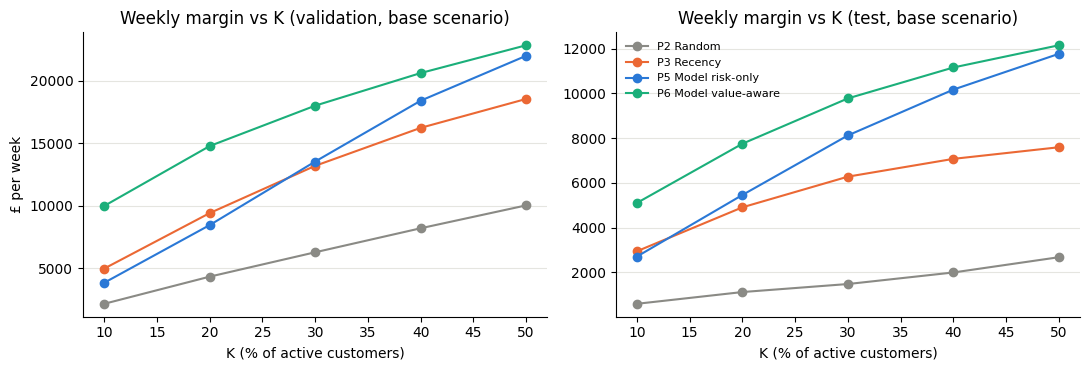

,K=10%,K=20%,K=30%,K=40%,K=50%
P2 Random,598.0,1124.0,1482.0,1998.0,2680.0
P3 Recency,2947.0,4911.0,6281.0,7075.0,7594.0
P5 Model risk-only,2711.0,5463.0,8124.0,10172.0,11770.0
P6 Model value-aware,5107.0,7753.0,9778.0,11160.0,12152.0


In [10]:
# Margin vs K for each ranking policy, validation and test
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
names = ["P2 Random", "P3 Recency", "P5 Model risk-only", "P6 Model value-aware"]
colors = [GREY, ORANGE, BLUE, GREEN]
curves = {}
for ax, (split, df) in zip(axes, [("validation", val), ("test", test)]):
    for n, col in zip(names, colors):
        ys = [policy_table(df, k, SC_BASE).loc[n, "margin_week_mean"] for k in K_GRID]
        curves[(split, n)] = ys
        ax.plot([int(k * 100) for k in K_GRID], ys, marker="o", label=n, color=col)
    ax.set_title(f"Weekly margin vs K ({split}, base scenario)"); ax.set_xlabel("K (% of active customers)")
axes[0].set_ylabel("£ per week"); axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig("../report/figures/ch10_policy_vs_k.png", dpi=150, bbox_inches="tight"); plt.show()
pd.DataFrame({f"K={int(k*100)}%": {n: curves[("test", n)][i] for n in names} for i, k in enumerate(K_GRID)}).round(0)

**Reading.** Under the Strategy v2 margin model (cannibalization proportional
to V·d), the value-aware policy P6 has the highest weekly margin at every K on
both validation and test. Risk-only P5 is still below the recency rule at
K=10% and overtakes it at K≈20% (test) or K≈30% (validation).

**Caveat on blanket (P1).** Blanket contacts every active customer (~2,400 per
week), so its total can exceed a K=20% policy when the discount is cheap
(Light scenario) even though its margin *per contact* is far lower
(≈£1.8 vs ≈£16 for P6 at base). Compare policies at equal budget (same K) and
look at margin per contact; blanket becomes strongly negative in the Deep scenario.

### 10.5b Where does the margin come from? Decomposition and break-even margin

Per policy at K=20%, base scenario, **test**, £ per week. `revenue_preserved`
is the expected revenue kept from targeted churners (e · V), the only revenue
effect in the model. The gross margin rate `m` is an **assumption**
(the dataset has revenue only, no cost or margin); `break_even_margin_rate`
is the gross margin at which the policy's net margin is zero: the policy pays
off if the true margin exceeds it.

In [11]:
rows = {}
_, masks = policy_masks(test, K_OP, SC_BASE)
for name, mk in masks.items():
    if name == "P0 No offer": continue
    rows[name] = margin_breakdown(test, mk, SC_BASE)
decomp = pd.DataFrame(rows).T
display(decomp.round(2))
d_, e_, m_, r_, c_ = SC_BASE
chk = weekly_margin(test, masks["P6 Model value-aware"], SC_BASE).mean()
assert abs(chk - decomp.loc["P6 Model value-aware", "net_margin_week"]) < 1e-6

,contacts_week,revenue_preserved_week,gross_margin_week,discount_on_responders_week,discount_wasted_on_buyers_week,contact_cost_week,net_margin_week,break_even_margin_rate
P1 Blanket,2425.2,96653.64,38661.46,-9665.36,-23363.63,-1212.60,4419.86,0.35
P2 Random,485.0,19929.97,7971.99,-1993.00,-4612.84,-242.50,1123.65,0.34
P3 Recency,485.0,27497.71,10999.09,-2749.77,-3096.01,-242.50,4910.80,0.22
P4 RFM At Risk+Can't Lose,773.2,38003.66,15201.47,-3800.37,-7014.30,-386.60,4000.20,0.29
P4b RFM validated segments,1020.3,53463.19,21385.28,-5346.32,-5119.18,-510.15,10409.63,0.21
P5 Model risk-only,485.0,25281.27,10112.51,-2528.13,-1879.01,-242.50,5462.87,0.18
P6 Model value-aware,485.0,39030.41,15612.17,-3903.04,-3713.66,-242.50,7752.97,0.20


In [12]:
# Break-even margin by scenario (K=20%): lower is safer
rows = []
for sname, (d, e) in SCENARIOS.items():
    scen = (d, e, BASE["m"], BASE["r"], BASE["c"])
    _, mk = policy_masks(test, K_OP, scen)
    rows.append({"scenario": sname, **{n: margin_breakdown(test, m_, scen)["break_even_margin_rate"] for n, m_ in mk.items() if n != "P0 No offer"}})
pd.DataFrame(rows).set_index("scenario").round(3)

,P1 Blanket,P2 Random,P3 Recency,P4 RFM At Risk+Can't Lose,P4b RFM validated segments,P5 Model risk-only,P6 Model value-aware
scenario,,,,,,,
Light,0.250,0.242,0.148,0.204,0.136,0.120,0.135
Base,0.354,0.344,0.221,0.295,0.205,0.184,0.201
Deep,0.572,0.556,0.376,0.484,0.351,0.319,0.327


## 10.6 Selection on validation, one evaluation on test

Rule: among P2/P3/P5/P6, choose the policy with the highest weekly validation
margin per scenario; then report it on test (no further tuning).

In [13]:
rows = []
for sname, (d, e) in SCENARIOS.items():
    scen = (d, e, BASE["m"], BASE["r"], BASE["c"])
    for k in K_GRID:
        tv = policy_table(val, k, scen).loc[names, "margin_week_mean"]
        tt = policy_table(test, k, scen)
        chosen = tv.idxmax()
        rows.append(dict(scenario=sname, K=f"{int(k*100)}%", chosen_on_validation=chosen,
                         test_margin_week=tt.loc[chosen, "margin_week_mean"],
                         recency_test=tt.loc["P3 Recency", "margin_week_mean"],
                         blanket_test=tt.loc["P1 Blanket", "margin_week_mean"],
                         best_in_test=tt.loc[names, "margin_week_mean"].idxmax()))
sel = pd.DataFrame(rows)
sel["vs_recency"] = sel.test_margin_week - sel.recency_test
sel["vs_blanket"] = sel.test_margin_week - sel.blanket_test
sel.round(0)

,scenario,K,chosen_on_validation,test_margin_week,recency_test,blanket_test,best_in_test,vs_recency,vs_blanket
0,Light,10%,P6 Model value-aware,4977.0,2644.0,9658.0,P6 Model value-aware,2333.0,-4681.0
1,Light,20%,P6 Model value-aware,7402.0,4626.0,9658.0,P6 Model value-aware,2776.0,-2256.0
2,Light,30%,P6 Model value-aware,9420.0,6187.0,9658.0,P6 Model value-aware,3233.0,-239.0
3,Light,40%,P6 Model value-aware,10859.0,7367.0,9658.0,P6 Model value-aware,3492.0,1201.0
4,Light,50%,P6 Model value-aware,11821.0,8370.0,9658.0,P6 Model value-aware,3451.0,2163.0
5,Base,10%,P6 Model value-aware,5107.0,2947.0,4420.0,P6 Model value-aware,2160.0,687.0
6,Base,20%,P6 Model value-aware,7753.0,4911.0,4420.0,P6 Model value-aware,2842.0,3333.0
7,Base,30%,P6 Model value-aware,9778.0,6281.0,4420.0,P6 Model value-aware,3497.0,5358.0
8,Base,40%,P6 Model value-aware,11160.0,7075.0,4420.0,P6 Model value-aware,4084.0,6740.0
9,Base,50%,P6 Model value-aware,12152.0,7594.0,4420.0,P6 Model value-aware,4558.0,7732.0


## 10.7 Sensitivity and wholesale influence

(a) Scenario grid d/e × m × r at K=20% (test). (b) Value capped at P99 vs
uncapped raw AOV vs dropping the top-1% customers. (c) Suppression run:
customers contacted in the previous 4 weeks are not contacted again.

In [14]:
rows = []
for sname, (d, e) in SCENARIOS.items():
    for m in [0.3, 0.4, 0.5]:
        for r in [0.2, 0.4, 0.6]:
            t = policy_table(test, K_OP, (d, e, m, r, BASE["c"])).loc[names + ["P1 Blanket"], "margin_week_mean"]
            rows.append(dict(scenario=sname, m=m, r=r, **t.round(0).to_dict(), winner=t[names].idxmax()))
grid = pd.DataFrame(rows)
display(grid)
print("Winner counts over the 27-cell grid:", grid.winner.value_counts().to_dict())
print("Cells where P6 > P3 Recency:", int((grid["P6 Model value-aware"] > grid["P3 Recency"]).sum()), "/ 27;",
      "P6 > blanket:", int((grid["P6 Model value-aware"] > grid["P1 Blanket"]).sum()), "/ 27")

,scenario,m,r,P2 Random,P3 Recency,P5 Model risk-only,P6 Model value-aware,P1 Blanket,winner
0,Light,0.3,0.2,1926.0,3566.0,3501.0,5853.0,9055.0,P6 Model value-aware
1,Light,0.3,0.4,773.0,2792.0,3032.0,4453.0,3215.0,P6 Model value-aware
2,Light,0.3,0.6,-380.0,2018.0,2562.0,3372.0,-2626.0,P6 Model value-aware
3,Light,0.4,0.2,3255.0,5400.0,5187.0,8851.0,15499.0,P6 Model value-aware
4,Light,0.4,0.4,2101.0,4626.0,4717.0,7402.0,9658.0,P6 Model value-aware
5,Light,0.4,0.6,948.0,3852.0,4247.0,6047.0,3817.0,P6 Model value-aware
6,Light,0.5,0.2,4583.0,7233.0,6872.0,11946.0,21943.0,P6 Model value-aware
7,Light,0.5,0.4,3430.0,6459.0,6402.0,10430.0,16102.0,P6 Model value-aware
8,Light,0.5,0.6,2277.0,5685.0,5933.0,9025.0,10261.0,P6 Model value-aware
9,Base,0.3,0.2,1437.0,3709.0,3874.0,5936.0,6436.0,P6 Model value-aware


Winner counts over the 27-cell grid: {'P6 Model value-aware': 27}
Cells where P6 > P3 Recency: 27 / 27; P6 > blanket: 16 / 27


In [15]:
def with_value(df, col):
    x = df.copy(); x["value_v"] = x[col]; return x
res = {}
variants = {"capped (P99, default)": test, "uncapped raw AOV": with_value(test, "avg_order_value_so_far"),
            "drop top-1% customers": test[~test.customer_id.isin(top1)]}
for lab, df in variants.items():
    t = policy_table(df, K_OP, SC_BASE).loc[names, "margin_week_mean"]
    res[lab] = t
pd.DataFrame(res).T.round(0)

,P2 Random,P3 Recency,P5 Model risk-only,P6 Model value-aware
"capped (P99, default)",1124.0,4911.0,5463.0,7753.0
uncapped raw AOV,1399.0,5840.0,5463.0,9973.0
drop top-1% customers,1170.0,4832.0,5423.0,7265.0


In [16]:
# Suppression: a customer contacted in the last S weeks is removed from the next week's pool
def suppressed_run(df, policy_col, k, scen, S=4):
    d, e, m, r, c = scen
    df = df.assign(em=expected_margin(df.p, df.value_v, d, e, m, r, c))
    weeks = sorted(df.snapshot_date.unique()); contacted = {}  # customer -> last contact week index
    total, n_contacts, uniq = [], [], set()
    for i, w in enumerate(weeks):
        wk = df[df.snapshot_date == w]
        elig = wk[[(contacted.get(cid, -99) < i - S) for cid in wk.customer_id]]
        n = max(int(round(len(wk) * k)), 1)  # budget fixed on the full pool
        pick = elig.nlargest(n, policy_col)
        if policy_col == "em": pick = pick[pick.em > 0]
        for cid in pick.customer_id: contacted[cid] = i
        uniq.update(pick.customer_id); n_contacts.append(len(pick))
        total.append(pd.Series(row_gain(pick, d, e, m, r, c)).sum())
    return np.mean(total), np.mean(n_contacts), len(uniq)

rows = {}
for lab, col in [("P3 Recency", "recency_days"), ("P5 Model risk-only", "p"), ("P6 Model value-aware", "em")]:
    base_m = policy_table(test, K_OP, SC_BASE).loc[lab, "margin_week_mean"]
    sm, sc_, su = suppressed_run(test, col, K_OP, SC_BASE)
    rows[lab] = dict(no_suppression_week=base_m, suppression_4w_week=sm, contacts_per_week=sc_, unique_customers_contacted=su)
pd.DataFrame(rows).T.round(0)

,no_suppression_week,suppression_4w_week,contacts_per_week,unique_customers_contacted
P3 Recency,4911.0,1618.0,484.0,2828.0
P5 Model risk-only,5463.0,1939.0,485.0,2847.0
P6 Model value-aware,7753.0,3067.0,313.0,1941.0


**Multi-week note.** Weekly Top-K re-selects the same at-risk customers
week after week. The weekly figures above are per-week campaign margins; the
sum over 10 weeks overstates a real campaign because (i) the 90-day windows
overlap and (ii) the same customer is counted repeatedly. The suppression run
shows the effect of not re-contacting within 4 weeks.

## 10.8 Customer-level recommendation table

In [17]:
# Action rule (initial, configurable): Retain = P6 selected at K; Nurture = high risk but E[dM] <= 0; No-offer = rest
def build_actions(df, k, scen):
    d, e, m, r, c = scen
    df = df.assign(expected_margin=expected_margin(df.p, df.value_v, d, e, m, r, c))
    sel_k = top_k_mask(df, "expected_margin", k) & (df.expected_margin > 0)
    high_risk = df.groupby("snapshot_date")["p"].rank(pct=True) >= 0.8
    df["action"] = np.where(sel_k, "Retain", np.where(high_risk, "Nurture", "No-offer"))
    df["rank_by_margin"] = df.groupby("snapshot_date").expected_margin.rank(ascending=False, method="first").astype(int)
    return df

actions = build_actions(test, K_OP, SC_BASE)
print(actions.groupby("action").agg(rows=("churn", "size"), churn=("churn", "mean"), value_v=("value_v", "mean"), p=("p", "mean")).round(3))
print("Realized weekly margin of the action list (Retain only):",
      round(weekly_margin(actions, actions.action == "Retain", SC_BASE).mean(), 0))
cols = ["customer_id", "snapshot_date", "split", "p", "value_v", "rfm_segment", "expected_margin", "rank_by_margin", "action", "churn"]
out = pd.concat([build_actions(val, K_OP, SC_BASE).assign(split="validation"), actions.assign(split="test")])[cols]
out = out.rename(columns={"p": "churn_probability"})
out["model_version"] = "lr_extended_c0.01_weighted_h90_trainonly"
out.to_parquet("../data/results/customer_analysis_h90.parquet", index=False)
print("saved customer_analysis_h90.parquet:", out.shape)

           rows  churn  value_v      p
action                                
No-offer  17626  0.312  376.022  0.268
Nurture    1776  0.722  115.712  0.710
Retain     4850  0.604  459.676  0.627
Realized weekly margin of the action list (Retain only): 7753.0
saved customer_analysis_h90.parquet: (45766, 11)


## 10.9 Notes and caveats

* No treatment/control data: all margins are scenario estimates. Policy *ranking*
  across 27 assumption cells is the robust output; absolute £ are not ROI.
* P6 ranks with the same `e`, `r`, `m`, `d` assumptions that the margin
  evaluation uses; the ranking advantage still depends on real labels and V.
* Probabilities are not recalibrated (10.2); the base rate shifts with season.
* The test window (Jul-Sep 2011) has the lowest churn of the year and no Christmas peak.